**Cell 1: Mount Drive, Install Libraries, & Unzip Dataset**

In [ ]:
import os
import zipfile
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Install Pustaka yang Dibutuhkan
!pip install timm scikit-learn matplotlib seaborn -q

# 3. Path Dataset & Direktori Output
zip_path = '/content/drive/MyDrive/Proyek Semester 7/Dataset/Dataset yang digunakan/Dataset ( 0, 1 )/New Dataset.v1i.folder.zip'
extract_path = '/content/dataset'
save_dir = '/content/drive/MyDrive/Proyek Semester 7/Hasil Model/Hasil Model Classification/Unimodal/CNN Terbaru'

os.makedirs(extract_path, exist_ok=True)
os.makedirs(save_dir, exist_ok=True)

# 4. Unzip Dataset ke Direktori Lokal Colab (Agar I/O Training Cepat)
print("Ekstraksi dataset sedang berlangsung...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
print("Ekstraksi selesai!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ekstraksi dataset sedang berlangsung...
Ekstraksi selesai!


**Cell 2: Setup Data Augmentation, DataLoader, & Computation Weighted Loss**

In [ ]:
import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import numpy as np

# Konfigurasi Perangkat & Parameter
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32
IMAGE_SIZE = 224

# Transformasi Data
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Memuat Dataset
train_dataset = datasets.ImageFolder(root=os.path.join(extract_path, 'train'), transform=train_transform)
val_dataset = datasets.ImageFolder(root=os.path.join(extract_path, 'valid'), transform=val_test_transform)
test_dataset = datasets.ImageFolder(root=os.path.join(extract_path, 'test'), transform=val_test_transform)

# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

class_names = train_dataset.classes
print(f"Daftar Kelas ({len(class_names)}): {class_names}")

# MENGHITUNG WEIGHTED LOSS UNTUK HANDLING DATA IMBALANCE
class_counts = np.bincount(train_dataset.targets)
total_samples = len(train_dataset)
class_weights = total_samples / (len(class_names) * class_counts)
class_weights_tensor = torch.FloatTensor(class_weights).to(device)

print("\nBobot Penalti Per Kelas (Weighted Loss):")
for name, weight in zip(class_names, class_weights):
    print(f" - {name}: {weight:.4f}")

Daftar Kelas (7): ['Bacterial_Spot', 'Fusarium', 'Healthy', 'Leaf Blight', 'Leaf Curl', 'Mosaic', 'Septoria']

Bobot Penalti Per Kelas (Weighted Loss):
 - Bacterial_Spot: 0.8237
 - Fusarium: 1.0306
 - Healthy: 0.5359
 - Leaf Blight: 5.0142
 - Leaf Curl: 0.8574
 - Mosaic: 0.8574
 - Septoria: 2.3951


**Cell 3: Fungsi Training Loop, Evaluasi, dan Visualisasi Metrik**

In [ ]:
import os
import torch
import torch.nn as nn
import timm
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

def train_and_evaluate_model(model_name, timm_model_str, epochs=30):
    print(f"\n==================================================")
    print(f"   MEMULAI TRAINING MODEL: {model_name}")
    print(f"==================================================")

    # Init Model dari timm
    model = timm.create_model(timm_model_str, pretrained=True, num_classes=len(class_names))
    model = model.to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_val_loss = float('inf')
    save_path = os.path.join(save_dir, f"best_{model_name.lower().replace(' ', '_')}.pt")

    # Loop Training
    for epoch in range(epochs):
        model.train()
        train_loss, train_correct = 0.0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            train_correct += torch.sum(preds == labels.data)

        scheduler.step()
        epoch_train_loss = train_loss / len(train_dataset)
        epoch_train_acc = train_correct.double() / len(train_dataset)

        # Validasi
        model.eval()
        val_loss, val_correct = 0.0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += torch.sum(preds == labels.data)

        epoch_val_loss = val_loss / len(val_dataset)
        epoch_val_acc = val_correct.double() / len(val_dataset)

        print(f"Epoch [{epoch+1:02d}/{epochs:02d}] | Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f} | Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}")

        # Simpan Best Model Checkpoint
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            torch.save(model.state_dict(), save_path)

    print(f"\nModel terbaik disimpan di: {save_path}")

    # ----------------------------------------------------
    # EVALUASI PADA TEST SET (REPORT & CONFUSION MATRIX)
    # ----------------------------------------------------
    print(f"\n--- EVALUASI AKHIR TEST SET ({model_name}) ---")
    model.load_state_dict(torch.load(save_path))
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    # Print Classification Report di Output Terminal
    print("\nCLASSIFICATION REPORT:")
    print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

    # Print & Plot Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.show()

**MobileNetV4**


   MEMULAI TRAINING MODEL: MobileNetV4


model.safetensors: reconstructing file:   0%|          |  0.00B / 15.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch [01/30] | Train Loss: 1.9841 Acc: 0.5493 | Val Loss: 1.2216 Acc: 0.6221
Epoch [02/30] | Train Loss: 0.8359 Acc: 0.7168 | Val Loss: 0.7115 Acc: 0.7469
Epoch [03/30] | Train Loss: 0.5625 Acc: 0.7857 | Val Loss: 0.6438 Acc: 0.7729
Epoch [04/30] | Train Loss: 0.4342 Acc: 0.8342 | Val Loss: 0.5924 Acc: 0.7922
Epoch [05/30] | Train Loss: 0.3417 Acc: 0.8622 | Val Loss: 0.4844 Acc: 0.8335
Epoch [06/30] | Train Loss: 0.2660 Acc: 0.8919 | Val Loss: 0.4560 Acc: 0.8456
Epoch [07/30] | Train Loss: 0.2416 Acc: 0.9095 | Val Loss: 0.4742 Acc: 0.8398
Epoch [08/30] | Train Loss: 0.2193 Acc: 0.9115 | Val Loss: 0.5044 Acc: 0.8402
Epoch [09/30] | Train Loss: 0.1772 Acc: 0.9299 | Val Loss: 0.4187 Acc: 0.8636
Epoch [10/30] | Train Loss: 0.1386 Acc: 0.9417 | Val Loss: 0.3714 Acc: 0.8752
Epoch [11/30] | Train Loss: 0.1182 Acc: 0.9537 | Val Loss: 0.3659 Acc: 0.8959
Epoch [12/30] | Train Loss: 0.1094 Acc: 0.9577 | Val Loss: 0.4593 Acc: 0.8703
Epoch [13/30] | Train Loss: 0.0986 Acc: 0.9583 | Val Loss: 0.343

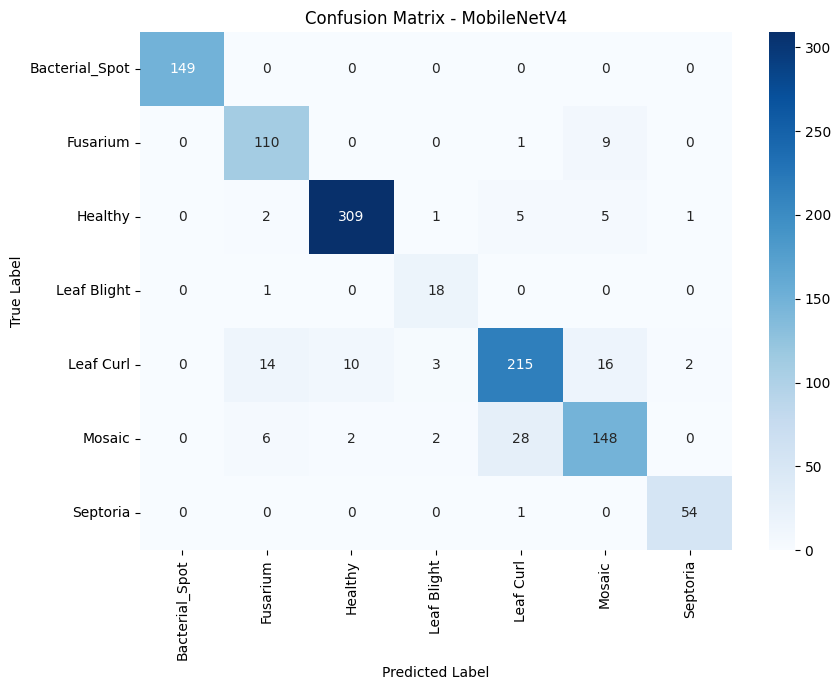

In [ ]:
train_and_evaluate_model(
    model_name="MobileNetV4",
    timm_model_str="mobilenetv4_conv_small.e2400_r224_in1k",
    epochs=30
)

**EfficientNetB5**


   MEMULAI TRAINING MODEL: EfficientNetB5


model.safetensors: reconstructing file:   0%|          |  0.00B /  122MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch [01/30] | Train Loss: 0.8815 Acc: 0.7596 | Val Loss: 0.4520 Acc: 0.8326
Epoch [02/30] | Train Loss: 0.2010 Acc: 0.9264 | Val Loss: 0.3744 Acc: 0.8793
Epoch [03/30] | Train Loss: 0.1254 Acc: 0.9565 | Val Loss: 0.3967 Acc: 0.8936
Epoch [04/30] | Train Loss: 0.0693 Acc: 0.9745 | Val Loss: 0.3153 Acc: 0.9134
Epoch [05/30] | Train Loss: 0.0317 Acc: 0.9893 | Val Loss: 0.2867 Acc: 0.9327
Epoch [06/30] | Train Loss: 0.0287 Acc: 0.9893 | Val Loss: 0.3439 Acc: 0.9273
Epoch [07/30] | Train Loss: 0.0688 Acc: 0.9767 | Val Loss: 0.4474 Acc: 0.9098
Epoch [08/30] | Train Loss: 0.0662 Acc: 0.9780 | Val Loss: 0.3067 Acc: 0.9246
Epoch [09/30] | Train Loss: 0.0562 Acc: 0.9833 | Val Loss: 0.3417 Acc: 0.9174
Epoch [10/30] | Train Loss: 0.0484 Acc: 0.9873 | Val Loss: 0.4274 Acc: 0.9156
Epoch [11/30] | Train Loss: 0.0187 Acc: 0.9933 | Val Loss: 0.3567 Acc: 0.9309
Epoch [12/30] | Train Loss: 0.0089 Acc: 0.9963 | Val Loss: 0.3671 Acc: 0.9322
Epoch [13/30] | Train Loss: 0.0064 Acc: 0.9980 | Val Loss: 0.396

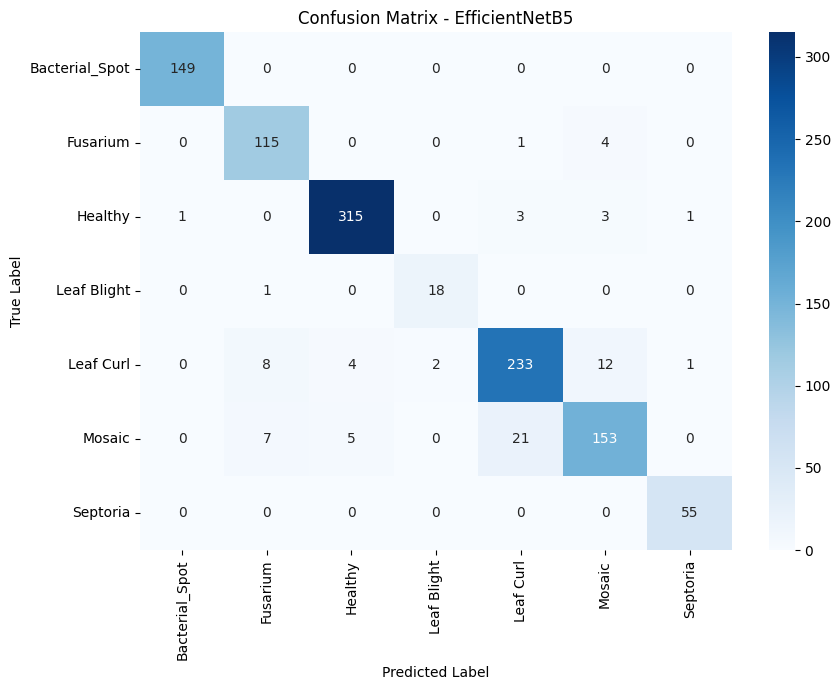

In [ ]:
train_and_evaluate_model(
    model_name="EfficientNetB5",
    timm_model_str="efficientnet_b5",
    epochs=30
)

**ConvNeXt**


   MEMULAI TRAINING MODEL: ConvNeXt


model.safetensors: reconstructing file:   0%|          |  0.00B /  201MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch [01/30] | Train Loss: 0.7780 Acc: 0.7033 | Val Loss: 0.6179 Acc: 0.7558
Epoch [02/30] | Train Loss: 0.3028 Acc: 0.8910 | Val Loss: 0.4282 Acc: 0.8546
Epoch [03/30] | Train Loss: 0.1899 Acc: 0.9332 | Val Loss: 0.4265 Acc: 0.8739
Epoch [04/30] | Train Loss: 0.0765 Acc: 0.9732 | Val Loss: 0.3904 Acc: 0.9026
Epoch [05/30] | Train Loss: 0.0700 Acc: 0.9755 | Val Loss: 0.5523 Acc: 0.8676
Epoch [06/30] | Train Loss: 0.0548 Acc: 0.9802 | Val Loss: 0.6920 Acc: 0.8402
Epoch [07/30] | Train Loss: 0.0471 Acc: 0.9827 | Val Loss: 0.2635 Acc: 0.9286
Epoch [08/30] | Train Loss: 0.0764 Acc: 0.9773 | Val Loss: 0.3452 Acc: 0.9264
Epoch [09/30] | Train Loss: 0.0375 Acc: 0.9867 | Val Loss: 0.4164 Acc: 0.9026
Epoch [10/30] | Train Loss: 0.0131 Acc: 0.9960 | Val Loss: 0.3223 Acc: 0.9322
Epoch [11/30] | Train Loss: 0.0035 Acc: 0.9985 | Val Loss: 0.3699 Acc: 0.9385
Epoch [12/30] | Train Loss: 0.0080 Acc: 0.9972 | Val Loss: 0.3521 Acc: 0.9192
Epoch [13/30] | Train Loss: 0.0334 Acc: 0.9895 | Val Loss: 0.632

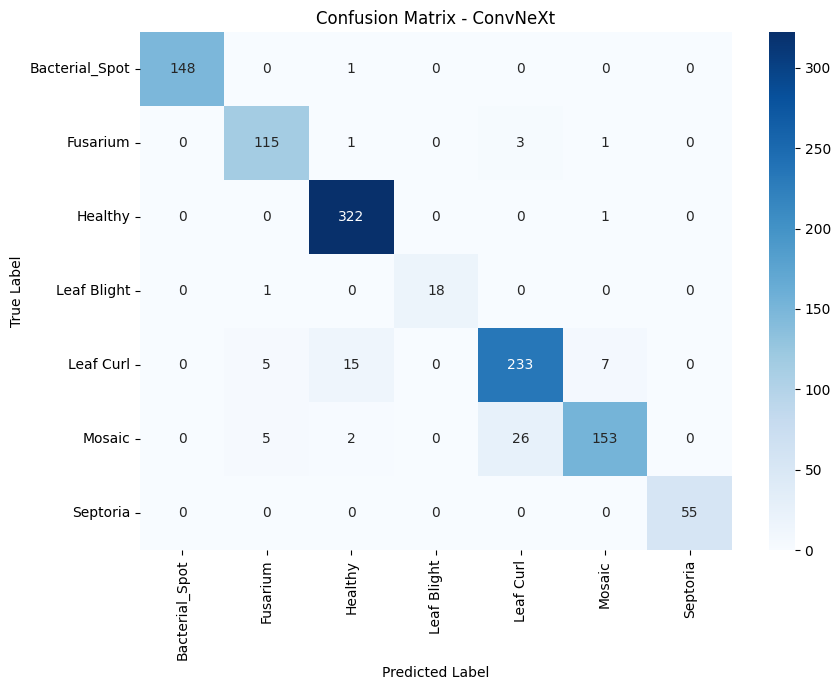

In [ ]:
train_and_evaluate_model(
    model_name="ConvNeXt",
    timm_model_str="convnext_small",
    epochs=30
)

**ResNet50d**


   MEMULAI TRAINING MODEL: ResNet50d


model.safetensors: reconstructing file:   0%|          |  0.00B /  103MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch [01/30] | Train Loss: 1.0391 Acc: 0.6508 | Val Loss: 0.5523 Acc: 0.7998
Epoch [02/30] | Train Loss: 0.3530 Acc: 0.8687 | Val Loss: 0.3876 Acc: 0.8456
Epoch [03/30] | Train Loss: 0.2028 Acc: 0.9235 | Val Loss: 0.3160 Acc: 0.8882
Epoch [04/30] | Train Loss: 0.1233 Acc: 0.9572 | Val Loss: 0.3279 Acc: 0.8950
Epoch [05/30] | Train Loss: 0.0924 Acc: 0.9638 | Val Loss: 0.3128 Acc: 0.9008
Epoch [06/30] | Train Loss: 0.0658 Acc: 0.9772 | Val Loss: 0.3566 Acc: 0.8999
Epoch [07/30] | Train Loss: 0.0439 Acc: 0.9857 | Val Loss: 0.2959 Acc: 0.9232
Epoch [08/30] | Train Loss: 0.0390 Acc: 0.9860 | Val Loss: 0.2825 Acc: 0.9228
Epoch [09/30] | Train Loss: 0.0312 Acc: 0.9890 | Val Loss: 0.3418 Acc: 0.9156
Epoch [10/30] | Train Loss: 0.0331 Acc: 0.9903 | Val Loss: 0.3268 Acc: 0.9237
Epoch [11/30] | Train Loss: 0.0345 Acc: 0.9903 | Val Loss: 0.3489 Acc: 0.9093
Epoch [12/30] | Train Loss: 0.0225 Acc: 0.9930 | Val Loss: 0.3088 Acc: 0.9241
Epoch [13/30] | Train Loss: 0.0187 Acc: 0.9957 | Val Loss: 0.288

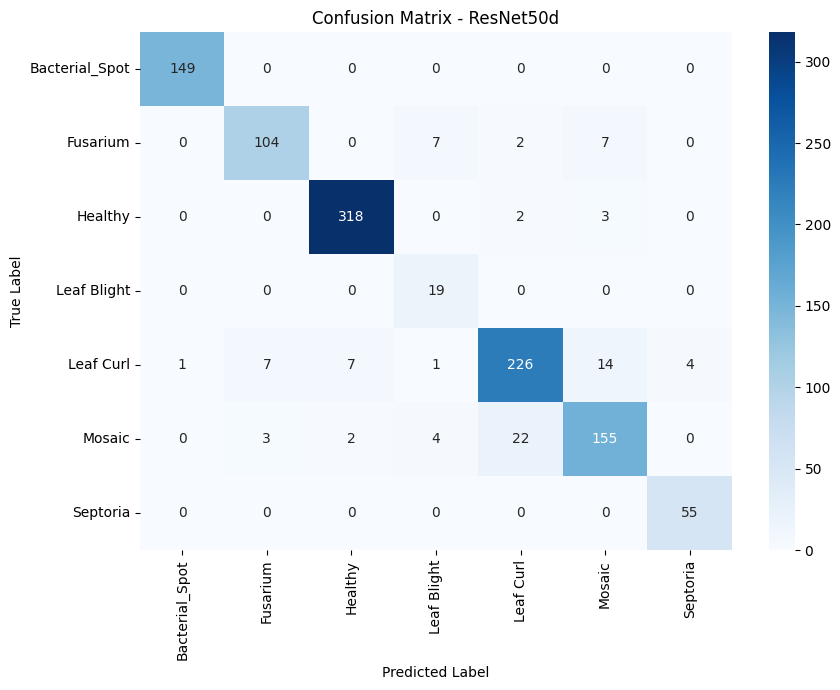

In [ ]:
train_and_evaluate_model(
    model_name="ResNet50d",
    timm_model_str="resnet50d",
    epochs=30
)

**DenseNet121**


   MEMULAI TRAINING MODEL: DenseNet121


model.safetensors: reconstructing file:   0%|          |  0.00B / 32.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch [01/30] | Train Loss: 0.9799 Acc: 0.6703 | Val Loss: 0.5775 Acc: 0.8066
Epoch [02/30] | Train Loss: 0.3818 Acc: 0.8722 | Val Loss: 0.3729 Acc: 0.8636
Epoch [03/30] | Train Loss: 0.2020 Acc: 0.9304 | Val Loss: 0.2945 Acc: 0.8986
Epoch [04/30] | Train Loss: 0.1393 Acc: 0.9532 | Val Loss: 0.2510 Acc: 0.9098
Epoch [05/30] | Train Loss: 0.0970 Acc: 0.9692 | Val Loss: 0.2770 Acc: 0.9071
Epoch [06/30] | Train Loss: 0.0814 Acc: 0.9753 | Val Loss: 0.2229 Acc: 0.9197
Epoch [07/30] | Train Loss: 0.0567 Acc: 0.9842 | Val Loss: 0.2434 Acc: 0.9237
Epoch [08/30] | Train Loss: 0.0490 Acc: 0.9840 | Val Loss: 0.2055 Acc: 0.9345
Epoch [09/30] | Train Loss: 0.0337 Acc: 0.9897 | Val Loss: 0.2064 Acc: 0.9345
Epoch [10/30] | Train Loss: 0.0264 Acc: 0.9918 | Val Loss: 0.2249 Acc: 0.9372
Epoch [11/30] | Train Loss: 0.0276 Acc: 0.9923 | Val Loss: 0.2197 Acc: 0.9304
Epoch [12/30] | Train Loss: 0.0301 Acc: 0.9902 | Val Loss: 0.2535 Acc: 0.9228
Epoch [13/30] | Train Loss: 0.0201 Acc: 0.9953 | Val Loss: 0.237

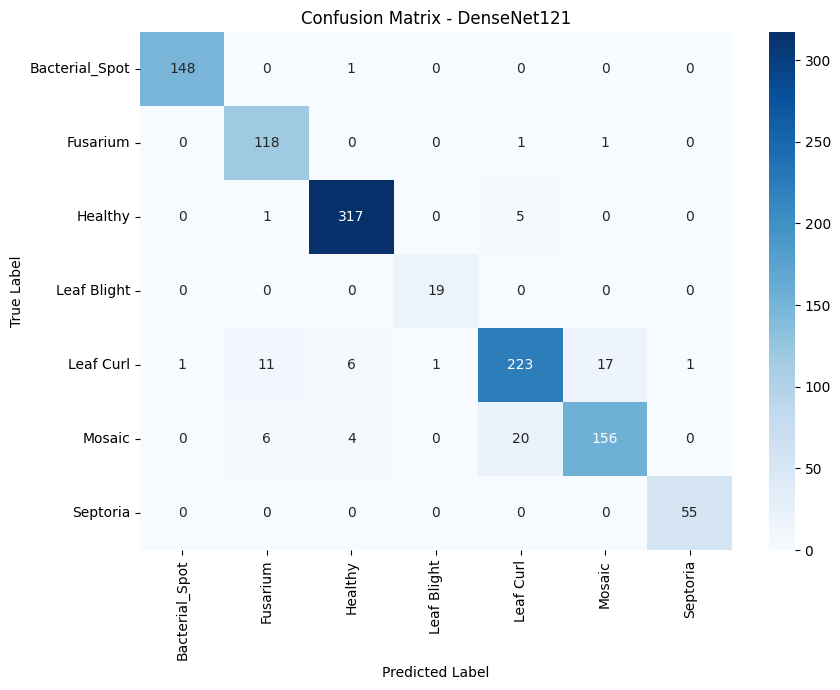

In [ ]:
train_and_evaluate_model(
    model_name="DenseNet121",
    timm_model_str="densenet121",
    epochs=30
)